# Offline BNN BCLF Surrogate Accuracy Study

This notebook trains the legacy Bayesian neural network surrogate on 80% of the cached BCLF dataset and compares predicted versus true S11/S21 responses and scalar objectives on both train and test splits.


In [1]:
from pathlib import Path
import csv
import importlib
import inspect
import json
import sys
import time

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import modeling.bclf_dataset as bclf_dataset_module
import modeling.legacy_bnn_surrogate as legacy_bnn_module

# Notebook kernels keep old class objects after source edits. Reload the modeling
# modules so TARGET_MODE="db" is always supported after rerunning this cell.
importlib.reload(bclf_dataset_module)
importlib.reload(legacy_bnn_module)

BCLFTouchstoneDatasetLoader = bclf_dataset_module.BCLFTouchstoneDatasetLoader
LegacyBNNResponseSurrogate = legacy_bnn_module.LegacyBNNResponseSurrogate
response_db = bclf_dataset_module.response_db

if "target_mode" not in inspect.signature(LegacyBNNResponseSurrogate.__init__).parameters:
    raise RuntimeError(
        "Loaded an old LegacyBNNResponseSurrogate without target_mode support. "
        "Restart the notebook kernel and rerun from the first cell."
    )

from optimization.optimization_spec import BCLFOptimizationSpec


In [2]:
def build_default_bclf_spec():
    return BCLFOptimizationSpec(
        passband_ghz=(4.8, 5.4),
        lower_stopband_ghz=(3.6, 4.4),
        upper_stopband_ghz=(5.8, 8.7),
        min_passband_s21_db=-5.0,
        max_passband_s11_db=-7.0,
        max_stopband_s21_db=-15.0,
        s11_weight=0.5,
        stopband_weight=0.5,
    )


def evaluate_objectives(dataset, spec):
    objectives = []
    details = []
    for idx in range(dataset.n_samples):
        result = spec.evaluate(dataset.freqs, dataset.s_params[idx])
        objectives.append(result.scalar_objective())
        details.append({
            "index": idx,
            "case_id": dataset.case_ids[idx],
            "objective": result.scalar_objective(),
            **result.metrics,
            **result.metadata,
        })
    return np.asarray(objectives, dtype=float), details


def write_csv(path, rows):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    if not rows:
        path.write_text("", encoding="utf-8")
        return
    fieldnames = sorted({key for row in rows for key in row.keys()})
    with path.open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(rows)



def read_csv_rows(path):
    path = Path(path)
    if not path.exists() or path.stat().st_size == 0:
        return []
    with path.open("r", newline="", encoding="utf-8") as f:
        rows = list(csv.DictReader(f))
    for row in rows:
        for key, value in list(row.items()):
            try:
                row[key] = float(value)
            except (TypeError, ValueError):
                row[key] = value
    return rows


def column(rows, name):
    return np.asarray([float(row[name]) for row in rows], dtype=float)


def show_rows(rows, limit=5):
    display(rows[:limit] if isinstance(rows, list) else rows)

def mae(a, b):
    return float(np.mean(np.abs(np.asarray(a, dtype=float) - np.asarray(b, dtype=float))))


def rankdata(values):
    order = np.argsort(values)
    ranks = np.empty(len(values), dtype=float)
    ranks[order] = np.arange(len(values), dtype=float)
    return ranks


def spearman(a, b):
    if len(a) < 2:
        return float("nan")
    ra = rankdata(np.asarray(a, dtype=float))
    rb = rankdata(np.asarray(b, dtype=float))
    if np.std(ra) < 1e-12 or np.std(rb) < 1e-12:
        return float("nan")
    return float(np.corrcoef(ra, rb)[0, 1])


def topk_recall(true_values, predicted_values, k):
    if k <= 0:
        return float("nan")
    true_top = set(np.argsort(true_values)[:k].tolist())
    pred_top = set(np.argsort(predicted_values)[:k].tolist())
    return float(len(true_top & pred_top) / k)



def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a, dtype=float) - np.asarray(b, dtype=float)) ** 2)))


def _prediction_rows_for_indices(dataset, spec, indices, pred_sparams):
    true_obj = np.asarray([spec.evaluate(dataset.freqs, dataset.s_params[int(idx)]).scalar_objective() for idx in indices], dtype=float)
    pred_obj = np.asarray([spec.evaluate(dataset.freqs, s).scalar_objective() for s in pred_sparams], dtype=float)
    rows = [
        {
            "dataset_index": int(idx),
            "case_id": dataset.case_ids[int(idx)],
            "true_objective": float(t),
            "pred_objective": float(p),
            "abs_objective_error": float(abs(t - p)),
        }
        for idx, t, p in zip(indices, true_obj, pred_obj)
    ]
    return rows, true_obj, pred_obj


def _holdout_metrics(split_name, train_fraction, seed, fit_seconds, indices, true_sparams, pred_sparams, true_obj, pred_obj):
    return {
        "split": split_name,
        "seed": seed,
        "train_fraction": float(train_fraction),
        "num_samples": int(len(indices)),
        "fit_seconds": float(fit_seconds),
        "s11_db_mae": mae(response_db(true_sparams, 0, 0), response_db(pred_sparams, 0, 0)),
        "s11_db_rmse": rmse(response_db(true_sparams, 0, 0), response_db(pred_sparams, 0, 0)),
        "s21_db_mae": mae(response_db(true_sparams, 1, 0), response_db(pred_sparams, 1, 0)),
        "s21_db_rmse": rmse(response_db(true_sparams, 1, 0), response_db(pred_sparams, 1, 0)),
        "objective_mae": mae(true_obj, pred_obj),
        "objective_rmse": rmse(true_obj, pred_obj),
        "objective_spearman": spearman(true_obj, pred_obj),
        "top10_recall": topk_recall(true_obj, pred_obj, k=min(10, len(true_obj))),
    }


def run_holdout_accuracy(dataset, spec, train_fraction, seed, bnn_kwargs):
    rng = np.random.default_rng(seed)
    all_idx = np.arange(dataset.n_samples)
    shuffled = rng.permutation(all_idx)
    train_count = int(round(dataset.n_samples * train_fraction))
    train_count = min(max(train_count, 1), dataset.n_samples - 1)
    train_idx = np.sort(shuffled[:train_count])
    test_idx = np.sort(shuffled[train_count:])

    model = LegacyBNNResponseSurrogate(seed=seed, **bnn_kwargs)
    start = time.perf_counter()
    model.fit(dataset, train_idx)
    fit_seconds = time.perf_counter() - start

    train_pred = model.predict_s_params(dataset, train_idx)
    test_pred = model.predict_s_params(dataset, test_idx)

    train_rows, train_true_obj, train_pred_obj = _prediction_rows_for_indices(dataset, spec, train_idx, train_pred)
    test_rows, test_true_obj, test_pred_obj = _prediction_rows_for_indices(dataset, spec, test_idx, test_pred)

    metrics = [
        _holdout_metrics(
            "train",
            train_fraction,
            seed,
            fit_seconds,
            train_idx,
            dataset.s_params[train_idx],
            train_pred,
            train_true_obj,
            train_pred_obj,
        ),
        _holdout_metrics(
            "test",
            train_fraction,
            seed,
            fit_seconds,
            test_idx,
            dataset.s_params[test_idx],
            test_pred,
            test_true_obj,
            test_pred_obj,
        ),
    ]
    return metrics, train_rows, test_rows, model, train_idx, test_idx, train_pred, test_pred


## Settings

In [ ]:
RUN_HOLDOUT_ACCURACY = True
USE_CACHED_RESULTS = False
FORCE_RETRAIN = True
TARGET_MODE = "db"  # Train S11/S21 dB directly.

DATASET_DIR = ROOT / "data" / "bandpass_coupled_line_filter_export" / "ext"
OUTPUT_DIR = ROOT / "experiments" / "bnn_bclf_offline_feasibility"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

HOLDOUT_TRAIN_FRACTION = 0.8
HOLDOUT_SEED = 0
MODEL_PATH = OUTPUT_DIR / f"legacy_bnn_{TARGET_MODE}_holdout_seed{HOLDOUT_SEED}.pt"
PREDICTION_CACHE_PATH = OUTPUT_DIR / f"legacy_bnn_{TARGET_MODE}_holdout_predictions.npz"
SPLIT_PATH = OUTPUT_DIR / "holdout_split.json"

BNN_KWARGS = {
    "epochs": 1000,
    "batch_size": 1024,
    "lr": 1e-3,
    "bayesian_loss_weight": 1e-4,
    "mc_samples": 50,
    "hidden_dims": [256, 256, 256],
    "target_mode": TARGET_MODE,
    "device": "cuda" if torch.cuda.is_available() else "cpu",
}

# After training once, set USE_CACHED_RESULTS=True and FORCE_RETRAIN=False for quick loading.
# For a quick syntax/runtime check, temporarily use:
# BNN_KWARGS.update({"epochs": 1, "batch_size": 64, "mc_samples": 2, "hidden_dims": [16]})


## Load Dataset And Objective

In [4]:
dataset = BCLFTouchstoneDatasetLoader(dataset_dir=DATASET_DIR).load()
spec = build_default_bclf_spec()
true_objectives, objective_details = evaluate_objectives(dataset, spec)

write_csv(OUTPUT_DIR / "objective_details.csv", objective_details)

dataset_summary = [
    {
        "num_samples": dataset.n_samples,
        "num_freqs": dataset.n_freqs,
        "freq_min_hz": float(dataset.freqs.min()),
        "freq_max_hz": float(dataset.freqs.max()),
        "best_objective": float(true_objectives.min()),
        "median_objective": float(np.median(true_objectives)),
    }
]
write_csv(OUTPUT_DIR / "dataset_summary.csv", dataset_summary)
show_rows(dataset_summary)


[{'num_samples': 157,
  'num_freqs': 401,
  'freq_min_hz': 3500000000.0,
  'freq_max_hz': 8700000000.0,
  'best_objective': -23.84930491778349,
  'median_objective': 20.718221647045617}]

## 80/20 BNN Surrogate Accuracy


In [5]:
if "run_holdout_accuracy" not in globals():
    raise RuntimeError("Run the helper-functions cell before the 80/20 BNN Surrogate Accuracy cell.")

holdout_metrics = []
holdout_train_rows = []
holdout_test_rows = []
holdout_model = None
holdout_train_idx = np.asarray([], dtype=int)
holdout_test_idx = np.asarray([], dtype=int)
holdout_train_pred_sparams = None
holdout_test_pred_sparams = None

metrics_path = OUTPUT_DIR / "holdout_accuracy_metrics.csv"
train_predictions_path = OUTPUT_DIR / "holdout_train_predictions.csv"
test_predictions_path = OUTPUT_DIR / "holdout_test_predictions.csv"
cache_ready = all(
    path.exists()
    for path in [metrics_path, train_predictions_path, test_predictions_path, PREDICTION_CACHE_PATH, SPLIT_PATH, MODEL_PATH]
)

if USE_CACHED_RESULTS and cache_ready and not FORCE_RETRAIN:
    holdout_metrics = read_csv_rows(metrics_path)
    holdout_train_rows = read_csv_rows(train_predictions_path)
    holdout_test_rows = read_csv_rows(test_predictions_path)
    split_payload = json.loads(SPLIT_PATH.read_text(encoding="utf-8"))
    holdout_train_idx = np.asarray(split_payload["train_indices"], dtype=int)
    holdout_test_idx = np.asarray(split_payload["test_indices"], dtype=int)
    pred_cache = np.load(PREDICTION_CACHE_PATH)
    holdout_train_pred_sparams = pred_cache["train_pred_sparams"]
    holdout_test_pred_sparams = pred_cache["test_pred_sparams"]
    holdout_model = LegacyBNNResponseSurrogate.load(MODEL_PATH, device="cpu")
    print(f"Loaded cached dB holdout results from {OUTPUT_DIR}")
elif RUN_HOLDOUT_ACCURACY:
    print(f"Training dB BNN surrogate for {BNN_KWARGS['epochs']} epochs")
    (
        holdout_metrics,
        holdout_train_rows,
        holdout_test_rows,
        holdout_model,
        holdout_train_idx,
        holdout_test_idx,
        holdout_train_pred_sparams,
        holdout_test_pred_sparams,
    ) = run_holdout_accuracy(
        dataset=dataset,
        spec=spec,
        train_fraction=HOLDOUT_TRAIN_FRACTION,
        seed=HOLDOUT_SEED,
        bnn_kwargs=BNN_KWARGS,
    )
    write_csv(metrics_path, holdout_metrics)
    write_csv(train_predictions_path, holdout_train_rows)
    write_csv(test_predictions_path, holdout_test_rows)
    holdout_model.save(
        MODEL_PATH,
        metadata={
            "train_fraction": HOLDOUT_TRAIN_FRACTION,
            "seed": HOLDOUT_SEED,
            "target_mode": TARGET_MODE,
        },
    )
    np.savez_compressed(
        PREDICTION_CACHE_PATH,
        train_indices=holdout_train_idx,
        test_indices=holdout_test_idx,
        train_pred_sparams=holdout_train_pred_sparams,
        test_pred_sparams=holdout_test_pred_sparams,
    )
    SPLIT_PATH.write_text(
        json.dumps({
            "train_indices": holdout_train_idx.tolist(),
            "test_indices": holdout_test_idx.tolist(),
            "train_fraction": HOLDOUT_TRAIN_FRACTION,
            "seed": HOLDOUT_SEED,
            "target_mode": TARGET_MODE,
        }, indent=2),
        encoding="utf-8",
    )

show_rows(holdout_metrics, limit=10)
show_rows(holdout_train_rows)
show_rows(holdout_test_rows)


Training dB BNN surrogate for 1000 epochs


100%|██████████| 1000/1000 [08:55<00:00,  1.87epoch/s, Epoch 1000/1000, Loss: 0.0530]


[{'split': 'train',
  'seed': 0,
  'train_fraction': 0.8,
  'num_samples': 126,
  'fit_seconds': 536.694886405021,
  's11_db_mae': 0.16324946016182135,
  's11_db_rmse': 0.5323755905773816,
  's21_db_mae': 1.3852209538457998,
  's21_db_rmse': 1.812392130374789,
  'objective_mae': 5.84222447740724,
  'objective_rmse': 8.88261897847585,
  'objective_spearman': 0.9735493063367081,
  'top10_recall': 0.9},
 {'split': 'test',
  'seed': 0,
  'train_fraction': 0.8,
  'num_samples': 31,
  'fit_seconds': 536.694886405021,
  's11_db_mae': 0.8100805738128636,
  's11_db_rmse': 2.298066408830946,
  's21_db_mae': 2.969614604203413,
  's21_db_rmse': 4.739510391029592,
  'objective_mae': 22.631213613434326,
  'objective_rmse': 32.18185747233252,
  'objective_spearman': 0.37580645161290327,
  'top10_recall': 0.6}]

[{'dataset_index': 0,
  'case_id': 'bo_online_general_seed0_it0005',
  'true_objective': 10.501635094651402,
  'pred_objective': 15.801603763206344,
  'abs_objective_error': 5.299968668554943},
 {'dataset_index': 1,
  'case_id': 'bo_online_general_seed0_it0000',
  'true_objective': 46.49304976230782,
  'pred_objective': 56.10977245008616,
  'abs_objective_error': 9.616722687778342},
 {'dataset_index': 2,
  'case_id': 'bo_online_general_seed0_it0001',
  'true_objective': 64.23611034074813,
  'pred_objective': 73.60036860248701,
  'abs_objective_error': 9.364258261738883},
 {'dataset_index': 3,
  'case_id': 'bo_online_general_seed0_it0002',
  'true_objective': 38.214449192680625,
  'pred_objective': 39.36262319794363,
  'abs_objective_error': 1.1481740052630016},
 {'dataset_index': 4,
  'case_id': 'bo_online_general_seed0_it0003',
  'true_objective': 21.24952301327757,
  'pred_objective': 28.372299376434626,
  'abs_objective_error': 7.122776363157055}]

[{'dataset_index': 7,
  'case_id': 'bo_online_general_seed0_it0007',
  'true_objective': 19.262875319490945,
  'pred_objective': 17.011330554719724,
  'abs_objective_error': 2.2515447647712215},
 {'dataset_index': 12,
  'case_id': 'bo_online_general_seed0_it0012',
  'true_objective': 17.867236140069558,
  'pred_objective': 20.033488393176707,
  'abs_objective_error': 2.1662522531071495},
 {'dataset_index': 14,
  'case_id': 'bo_online_general_seed0_it0014',
  'true_objective': 19.468202161045213,
  'pred_objective': 24.64083487999845,
  'abs_objective_error': 5.172632718953238},
 {'dataset_index': 29,
  'case_id': 'bo_online_general_seed0_it0029',
  'true_objective': 20.901674546513643,
  'pred_objective': 36.587131830959656,
  'abs_objective_error': 15.685457284446013},
 {'dataset_index': 31,
  'case_id': 'bo_online_general_seed0_it0031',
  'true_objective': 2.8217481401134528,
  'pred_objective': 25.133953260580927,
  'abs_objective_error': 22.312205120467475}]

## Plots

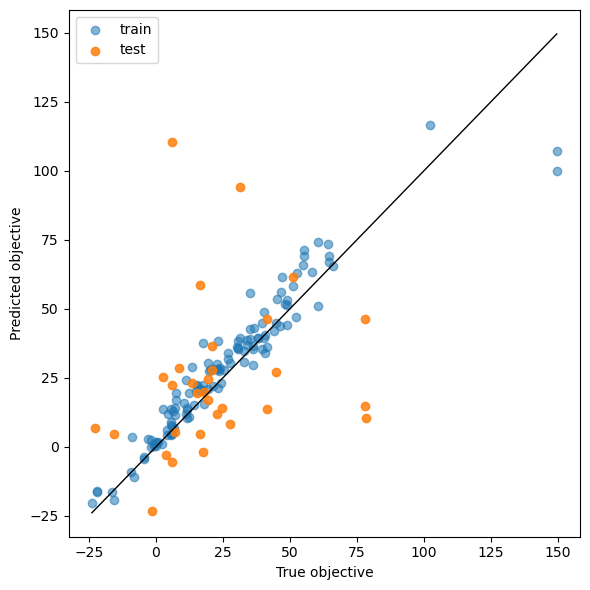

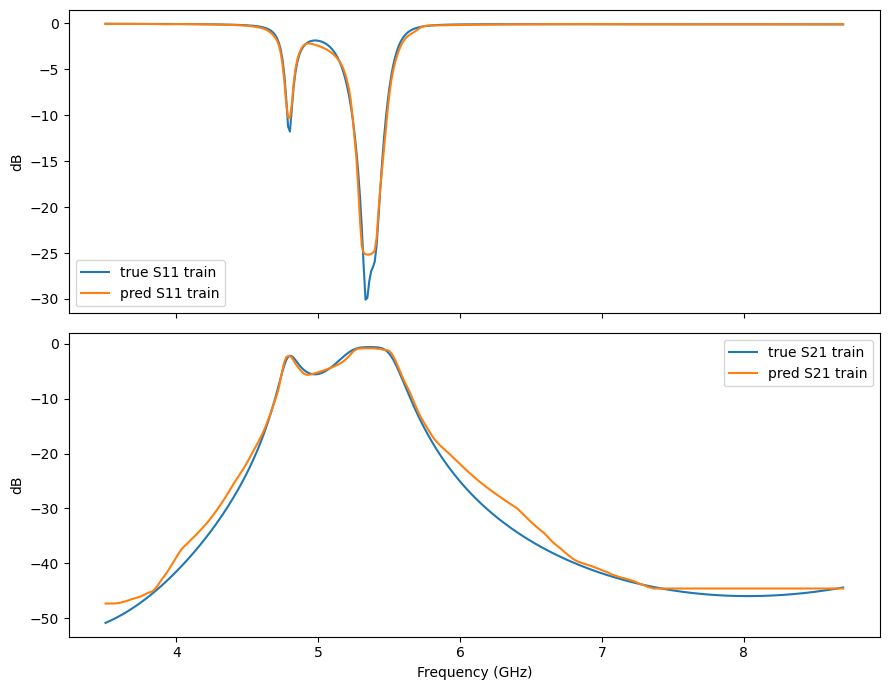

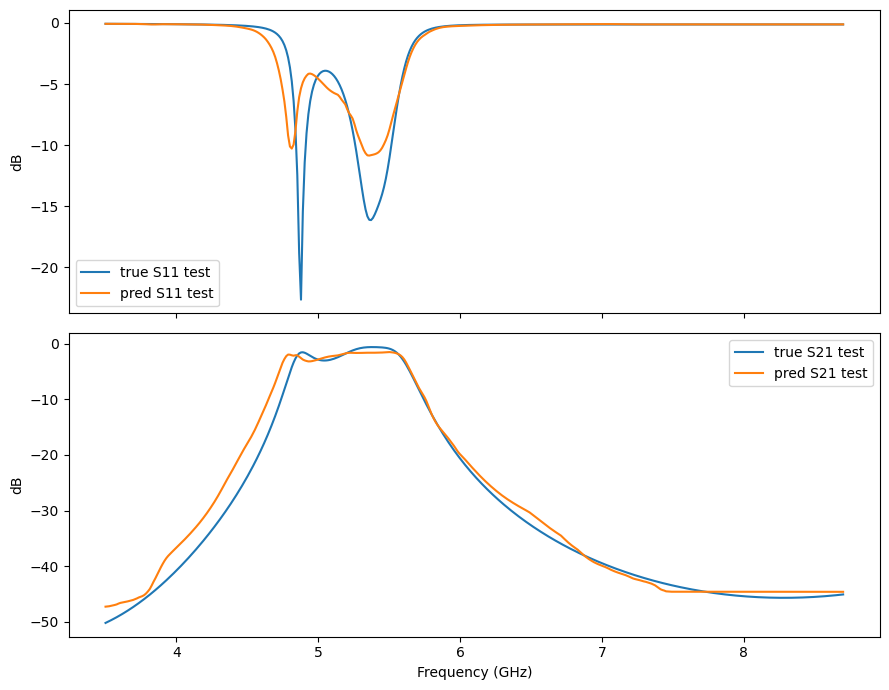

In [6]:
if holdout_train_rows and holdout_test_rows:
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(column(holdout_train_rows, "true_objective"), column(holdout_train_rows, "pred_objective"), alpha=0.55, label="train")
    ax.scatter(column(holdout_test_rows, "true_objective"), column(holdout_test_rows, "pred_objective"), alpha=0.85, label="test")
    all_true_pred = np.concatenate([
        column(holdout_train_rows, "true_objective"), column(holdout_train_rows, "pred_objective"),
        column(holdout_test_rows, "true_objective"), column(holdout_test_rows, "pred_objective"),
    ])
    lo = float(np.min(all_true_pred))
    hi = float(np.max(all_true_pred))
    ax.plot([lo, hi], [lo, hi], color="black", linewidth=1)
    ax.set_xlabel("True objective")
    ax.set_ylabel("Predicted objective")
    ax.legend()
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "holdout_train_test_objective_true_vs_pred.png", dpi=160)
    plt.show()


def plot_holdout_response_comparison(split_name, rows, indices, pred_sparams, filename):
    if pred_sparams is None or not rows or len(indices) == 0:
        return
    local_pos = int(np.argmin(column(rows, "abs_objective_error")))
    dataset_idx = int(indices[local_pos])
    pred = pred_sparams[[local_pos]]
    true = dataset.s_params[[dataset_idx]]
    fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
    axes[0].plot(dataset.freqs / 1e9, response_db(true, 0, 0)[0], label=f"true S11 {split_name}")
    axes[0].plot(dataset.freqs / 1e9, response_db(pred, 0, 0)[0], label=f"pred S11 {split_name}")
    axes[1].plot(dataset.freqs / 1e9, response_db(true, 1, 0)[0], label=f"true S21 {split_name}")
    axes[1].plot(dataset.freqs / 1e9, response_db(pred, 1, 0)[0], label=f"pred S21 {split_name}")
    for ax in axes:
        ax.set_ylabel("dB")
        ax.legend()
    axes[-1].set_xlabel("Frequency (GHz)")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / filename, dpi=160)
    plt.show()


plot_holdout_response_comparison(
    "train",
    holdout_train_rows,
    holdout_train_idx,
    holdout_train_pred_sparams,
    "holdout_train_best_response_prediction.png",
)
plot_holdout_response_comparison(
    "test",
    holdout_test_rows,
    holdout_test_idx,
    holdout_test_pred_sparams,
    "holdout_test_best_response_prediction.png",
)
